In [1]:
'''
estudio de cómo ha evolucionado la percepción del mundo a través del cine. 
¿El cine refleja la realidad social de su tiempo o refleja los problemas que la sociedad teme que puedan ocurrir?
estudiar no solo lo que le ocurría a la sociedad, sino también aquello que le preocupaba, 
    le aterrorizaba o le generaba incertidumbre en cada momento histórico.
'''

'\nestudio de cómo ha evolucionado la percepción del mundo a través del cine. \n¿El cine refleja la realidad social de su tiempo o refleja los problemas que la sociedad teme que puedan ocurrir?\nestudiar no solo lo que le ocurría a la sociedad, sino también aquello que le preocupaba, \n    le aterrorizaba o le generaba incertidumbre en cada momento histórico.\n'

## CAPÍTULO I — EL MUNDO DE ENTREGUERRAS
#### Estados Unidos, Reino Unido y Alemania (1919-1939)

Tras el final de la Primera Guerra Mundial, Europa y el resto del mundo se adentraron en una etapa marcada por profundos cambios sociales, económicos y políticos. Mientras algunas sociedades experimentaban crecimiento, modernización y nuevas formas de vida, otras se enfrentaban a la inestabilidad, el desempleo, la pobreza y el temor a un futuro incierto.

Entre 1919 y 1939, el cine se convirtió en un importante testigo de estas transformaciones. A través de sus historias y personajes, las películas reflejaron —de forma directa o indirecta— las preocupaciones de una sociedad que todavía intentaba recuperarse de la guerra y que avanzaba hacia un nuevo conflicto mundial.

En esta primera etapa, el análisis se centra en **Estados Unidos, Reino Unido y Alemania**, tres países que vivieron este periodo desde realidades muy diferentes.

### ¿Qué queremos investigar?

El objetivo es explorar cómo aparecen representadas en el cine cuatro grandes preocupaciones sociales de la época:

- **Pobreza (`poverty_score`):** presencia de dificultades económicas, desigualdad, precariedad y condiciones de vida desfavorables.
- **Desempleo (`unemployment_score`):** representación de la falta de trabajo, la inestabilidad laboral y sus consecuencias sobre la población.
- **Inestabilidad política (`political_instability_score`):** aparición de conflictos políticos, tensiones ideológicas, crisis institucionales y situaciones de agitación social.
- **Miedo al futuro (`fear_future_score`):** manifestaciones de incertidumbre, pesimismo, inseguridad y preocupación ante los acontecimientos futuros.

Además de medir la presencia de estas temáticas, se analiza **cómo se representan**:

- **Crítica (`critical`):** la película presenta una visión crítica de la situación o del fenómeno.
- **Humorística (`humorous`):** utiliza el humor o la sátira para abordar la temática.
- **Neutral (`neutral`):** muestra el contexto sin adoptar una postura claramente definida.
- **Positiva (`positive`):** ofrece una representación favorable o esperanzadora.

### Los datos sociales: el contexto detrás de las películas

Para contextualizar los resultados cinematográficos, se han recopilado dos indicadores externos que permiten aproximarse a la situación económica y política de los países estudiados durante el mismo periodo.

**1. PIB per cápita (`GDP per capita`)**

Este indicador representa el producto interior bruto de un país dividido entre su población. Se utiliza como aproximación al nivel de producción económica por habitante y permite observar la evolución de la situación económica de Estados Unidos, Reino Unido y Alemania.

Su comparación con las variables cinematográficas permitirá explorar si los cambios en el contexto económico coinciden con una mayor o menor presencia de temáticas como la pobreza, el desempleo o el miedo al futuro.

**2. Índice de democracia electoral (`v2x_polyarchy`)**

Obtenido de la base de datos V-Dem, este indicador mide el grado en que un país cumple las características de una democracia electoral, teniendo en cuenta aspectos como las elecciones, el sufragio, la libertad de expresión, la libertad de asociación y la existencia de elecciones libres y competitivas.

Sus valores permiten estudiar la evolución de las condiciones democráticas e institucionales de cada país y contrastarla con la presencia cinematográfica de la inestabilidad política.

### ¿Cómo se ha desarrollado el estudio?

El análisis parte de una selección de películas producidas entre 1919 y 1939 en los tres países estudiados. Una vez recopilada la información, se realiza un proceso de limpieza y preparación de los datos para facilitar su análisis.

El proceso se divide en varias fases:

1. **Recopilación cinematográfica:** selección de películas de Estados Unidos, Reino Unido y Alemania correspondientes al periodo 1919-1939.
2. **Limpieza y transformación:** tratamiento de valores ausentes, normalización de columnas y preparación de los datos para su análisis.
3. **Clasificación temática:** asignación de puntuaciones a las cuatro variables cinematográficas para cuantificar la presencia de cada temática.
4. **Análisis de la representación:** clasificación del enfoque narrativo de las películas y recopilación de justificaciones textuales.
5. **Recopilación de indicadores externos:** incorporación del PIB per cápita y del índice de democracia electoral, organizados por país y año.
6. **Comparación y visualización:** combinación de los datos cinematográficos y sociales para explorar tendencias, diferencias entre países y posibles relaciones.

Para realizar las comparaciones, se tendrán en cuenta tanto el país como el año, de manera que las puntuaciones cinematográficas puedan ponerse en contexto con los indicadores económicos y políticos correspondientes.

### El propósito

¿Reflejaba el cine las dificultades económicas de la sociedad de entreguerras? ¿Existían diferencias entre la forma en que Estados Unidos, Reino Unido y Alemania abordaban sus problemas? ¿Coincidían los periodos de mayor inestabilidad política con una mayor presencia de estas preocupaciones en las películas?

Estas son algunas de las preguntas que guían esta primera parte del proyecto.

El objetivo no es demostrar que la situación económica o política determina directamente el contenido de las películas, sino explorar si existen patrones y relaciones entre el contexto histórico y las representaciones cinematográficas.

**Porque, incluso entre fotogramas, historias y personajes, es posible encontrar las huellas de una sociedad que vivía entre las consecuencias del pasado y el miedo a lo que estaba por venir.**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.graph_objects as go

Filtramos los datos de my_movies.csv para quedarnos únicamente con las películas estrenadas entre 1919 y 1939, que tengan sinopsis, y que sean de Alemania, EEUU o Reino Unido.

In [3]:
my_movies=pd.read_csv("my_movies.csv")
my_movies

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
0,tt0000009,Miss Jerry,Miss Jerry,1894.0,Alexander Black,Romance,miss jerry,United States of America,After finding out that her father is suffering...,Silent film,United States,1890.0,371.0,64.0
1,tt0000147,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,1897.0,Enoch J. Rector,"Documentary,News,Sport",the corbett-fitzsimmons fight,NaN,The film no longer exists in its entirety; how...,NaN,NaN,1890.0,1190.0,195.0
2,tt0000502,Bohemios,Bohemios,1905.0,Ricardo de Baños,NaN,bohemios,NaN,NaN,NaN,NaN,1900.0,NaN,NaN
3,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906.0,Charles Tait,"Action,Adventure,Biography",the story of the kelly gang,Australia,The Story of the Kelly Gangs tone is of sorrow...,English Language,Australia,1900.0,1660.0,271.0
4,tt0000591,The Prodigal Son,L'enfant prodigue,1907.0,Michel Carré,Drama,the prodigal son,NaN,NaN,NaN,NaN,1900.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
759690,tt9916622,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,2015.0,NaN,Documentary,rodolpho teóphilo - o legado de um pioneiro,NaN,NaN,NaN,NaN,2010.0,NaN,NaN
759691,tt9916680,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,2007.0,Luis Ospina,Documentary,de la ilusión al desconcierto: cine colombiano...,NaN,NaN,NaN,NaN,2000.0,NaN,NaN
759692,tt9916706,Dankyavar Danka,Dankyavar Danka,2013.0,Kanchan Nayak,Comedy,dankyavar danka,NaN,NaN,NaN,NaN,2010.0,NaN,NaN
759693,tt9916730,6 Gunn,6 Gunn,2017.0,Kiran Gawade,Drama,6 gunn,NaN,NaN,NaN,NaN,2010.0,NaN,NaN


In [4]:
movies_ml = my_movies[my_movies["synopsis"].notna()].copy()
movies_ml["synopsis"] = movies_ml["synopsis"].str.strip()
movies_ml = movies_ml[movies_ml["synopsis"] != ""]
movies_ml = movies_ml.drop_duplicates(subset="movie_id")
movies_ml = movies_ml.reset_index(drop=True)
movies_ml

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
0,tt0000009,Miss Jerry,Miss Jerry,1894.0,Alexander Black,Romance,miss jerry,United States of America,After finding out that her father is suffering...,Silent film,United States,1890.0,371.0,64.0
1,tt0000147,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,1897.0,Enoch J. Rector,"Documentary,News,Sport",the corbett-fitzsimmons fight,NaN,The film no longer exists in its entirety; how...,NaN,NaN,1890.0,1190.0,195.0
2,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906.0,Charles Tait,"Action,Adventure,Biography",the story of the kelly gang,Australia,The Story of the Kelly Gangs tone is of sorrow...,English Language,Australia,1900.0,1660.0,271.0
3,tt0000615,Robbery Under Arms,Robbery Under Arms,1907.0,Charles MacMahon,Drama,robbery under arms,Australia,Key scenes of the film included the branding o...,Silent film,Australia,1900.0,463.0,81.0
4,tt0002646,Atlantis,Atlantis,1913.0,August Blom,Drama,atlantis,Denmark,"Dr. Friedrich von Kammacher , a surgeon, is de...","English Language, Danish Language",Denmark,1910.0,2933.0,529.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20037,tt9892692,Freeheld,Freeheld,NaN,NaN,Drama,freeheld,United States of America,"{{Plot|date""CWB"">{{Citation}} Stacie spends t...",English Language,United States,NaN,3144.0,532.0
20038,tt9896224,Untitled,Untitled,NaN,NaN,Drama,untitled,NaN,A filmmaker and his crew spend a weekend makin...,English Language,NaN,NaN,154.0,28.0
20039,tt9898210,Cowboy,Cowboy,NaN,Cameron Duddy,"Drama,Sport,Western",cowboy,United States of America,Frank Harris is a Chicago hotel clerk who dre...,English Language,United States,NaN,1767.0,319.0
20040,tt9900804,The Music Box,The Music Box,NaN,NaN,Thriller,the music box,United States of America,"In a music store, Mrs. Theodore von Schwartzen...",English Language,United States,NaN,2561.0,465.0


In [5]:
movies_ml["release_year"] = movies_ml["release_year"].astype("Int64")
peliculas_periodo = movies_ml[movies_ml["release_year"].between(1919, 1939)]
peliculas_periodo

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
99,tt0009878,Different from the Others,Anders als die Andern,1919,Richard Oswald,"Crime,Drama,History",different from the others,"Weimar Republic, Germany","Veidt portrays a successful violinist, Paul Kö...",German Language,Germany,1910.0,4477.0,745.0
100,tt0009893,The Oyster Princess,Die Austernprinzessin,1919,Ernst Lubitsch,Comedy,the oyster princess,Weimar Republic,The American oyster King dictates to a room fu...,"Silent film, German Language, English Language",Germany,1910.0,10442.0,1937.0
101,tt0009900,Back to God's Country,Back to God's Country,1919,David Hartford,"Adventure,Drama,Romance",back to god's country,Canada,"After her father is killed by an outlaw, Dolor...",English Language,Canada,1910.0,327.0,56.0
102,tt0010040,Daddy-Long-Legs,Daddy-Long-Legs,1919,Marshall Neilan,"Comedy,Drama,Musical",daddy-long-legs,United States of America,"A police officer finds a baby in a trash can, ...","Silent film, English Language",United States,1910.0,1255.0,217.0
103,tt0010081,The Echo of Youth,The Echo of Youth,1919,Ivan Abramson,Drama,the echo of youth,United States of America,Cabaret singer Olive Martin approaches her fo...,NaN,United States,1910.0,789.0,130.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10012,tt0336695,The Kid Stakes,The Kid Stakes,1927,Tal Ordell,Drama,the kid stakes,Australia,Fatty Finn is the six-year-old leader of a ga...,NaN,Australia,1920.0,364.0,64.0
10176,tt0353454,Fisher's Ghost,Fisher's Ghost,1924,Raymond Longford,"Drama,Thriller",fisher's ghost,NaN,The film is set in 1820s New South Wales. Two ...,"Silent film, English Language",NaN,1920.0,858.0,147.0
12440,tt0955292,The Lost City,The Lost City,1935,NaN,Sci-Fi,the lost city,United States of America,The film took the premise of that year's The P...,English Language,United States,1930.0,981.0,160.0
13813,tt1268864,The Blonde Captive,The Blonde Captive,1931,NaN,"Action,Adventure,Thriller",the blonde captive,"United States of America, Australia","Narrated by Explorer Lowell Thomas, Dr Paul Wi...",NaN,"United States, Australia",1930.0,979.0,160.0


In [6]:
peliculas_periodo=peliculas_periodo[peliculas_periodo["paises_norm"].isin(["Germany","United States","United Kingdom"])]
peliculas_periodo

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
99,tt0009878,Different from the Others,Anders als die Andern,1919,Richard Oswald,"Crime,Drama,History",different from the others,"Weimar Republic, Germany","Veidt portrays a successful violinist, Paul Kö...",German Language,Germany,1910.0,4477.0,745.0
100,tt0009893,The Oyster Princess,Die Austernprinzessin,1919,Ernst Lubitsch,Comedy,the oyster princess,Weimar Republic,The American oyster King dictates to a room fu...,"Silent film, German Language, English Language",Germany,1910.0,10442.0,1937.0
102,tt0010040,Daddy-Long-Legs,Daddy-Long-Legs,1919,Marshall Neilan,"Comedy,Drama,Musical",daddy-long-legs,United States of America,"A police officer finds a baby in a trash can, ...","Silent film, English Language",United States,1910.0,1255.0,217.0
103,tt0010081,The Echo of Youth,The Echo of Youth,1919,Ivan Abramson,Drama,the echo of youth,United States of America,Cabaret singer Olive Martin approaches her fo...,NaN,United States,1910.0,789.0,130.0
104,tt0010112,The False Faces,The False Faces,1919,Irvin Willat,"Drama,War",the false faces,United States of America,"During World War I, a professional thief known...","Silent film, English Language",United States,1910.0,320.0,55.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8458,tt0190518,The Lady of Red Butte,The Lady of Red Butte,1919,Victor Schertzinger,"Drama,Western",the lady of red butte,United States of America,Faro Fan inherits a saloon and gambling hall i...,"Silent film, English Language",United States,1910.0,313.0,53.0
8500,tt0196971,St. Elmo,St. Elmo,1923,Rex Wilson,Drama,st. elmo,United States of America,When St. Elmo Thornton catches his fiancée Agn...,"Silent film, English Language",United States,1920.0,342.0,58.0
8753,tt0229868,Zwei Menschen,Zwei Menschen,1930,Erich Waschneck,Drama,zwei menschen,Germany,Junker Rochus and Judith Platter are in love. ...,German Language,Germany,1930.0,460.0,78.0
12440,tt0955292,The Lost City,The Lost City,1935,NaN,Sci-Fi,the lost city,United States of America,The film took the premise of that year's The P...,English Language,United States,1930.0,981.0,160.0


Una vez que tenemos peliculas_periodo lista y filtrada, la exportaremos y, metiéndole un prompt a Gemini explicando bien todo el contexto, el objetivo y el resultado que queremos obtener, le pedimos que, por cada película 

In [7]:
peliculas_periodo.duplicated().sum()

np.int64(0)

In [8]:
peliculas_periodo[["title", "release_year","synopsis"]]

,title,release_year,synopsis
99,Different from the Others,1919,"Veidt portrays a successful violinist, Paul Kö..."
100,The Oyster Princess,1919,The American oyster King dictates to a room fu...
102,Daddy-Long-Legs,1919,"A police officer finds a baby in a trash can, ..."
103,The Echo of Youth,1919,Cabaret singer Olive Martin approaches her fo...
104,The False Faces,1919,"During World War I, a professional thief known..."
...,...,...,...
8458,The Lady of Red Butte,1919,Faro Fan inherits a saloon and gambling hall i...
8500,St. Elmo,1923,When St. Elmo Thornton catches his fiancée Agn...
8753,Zwei Menschen,1930,Junker Rochus and Judith Platter are in love. ...
12440,The Lost City,1935,The film took the premise of that year's The P...


Insertamos la tabla con los datos históricos de Índice de Democracia Electoral. Luego los filtraremos para quedarnos únicamente con los datos de Alemania, EEUU y Reino Unido entre 1919 y 1939.

In [9]:
v_dem=pd.read_csv("V-Dem-CY-Full+Others-v16.csv")
v_dem

C:\Users\jaime\AppData\Local\Temp\ipykernel_27876\2001168802.py:1: DtypeWarning: Columns (364: v2lpname, 365: v2slpname, 366: v2tlpname, 399: v2elregnam, 415: v2ellocnam, 804: v2exparhos, 836: v2exnamhog, 837: v2extithog, 924: v2expothog, 1240: v2lgnameup, 1257: v2lgnamelo, 1486: v2juhcname, 3094: v3lgcamoth, 3168: v3lgnamelo, 3169: v3lgnameup, 3341: v3exnamhos, 3342: v3exnamhog, 3344: v3extithos, 3345: v3extithog, 3347: v3elregnam, 3350: v3ellocnam, 3352: v3juhcname) have mixed types. Specify dtype option on import or set low_memory=False.
  v_dem=pd.read_csv("V-Dem-CY-Full+Others-v16.csv")


,country_name,country_text_id,country_id,year,historical_date,project,historical,histname,codingstart,codingend,...,e_pechmor,e_miinteco,e_civil_war,e_miinterc,e_pt_coup,e_pt_coup_attempts,e_ovexist_0,e_ovexist_1,e_ovexist_2,e_ovexist_3
0,Mexico,MEX,3,1789,1789-12-31,1,1,Viceroyalty of New Spain,1789,2025,...,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,Mexico,MEX,3,1790,1790-12-31,1,1,Viceroyalty of New Spain,1789,2025,...,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,Mexico,MEX,3,1791,1791-12-31,1,1,Viceroyalty of New Spain,1789,2025,...,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,Mexico,MEX,3,1792,1792-12-31,1,1,Viceroyalty of New Spain,1789,2025,...,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,Mexico,MEX,3,1793,1793-12-31,1,1,Viceroyalty of New Spain,1789,2025,...,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28087,Piedmont-Sardinia,SPD,373,1857,1857-12-31,1,1,Kingdom of Piedmont-Sardinia,1789,1861,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28088,Piedmont-Sardinia,SPD,373,1858,1858-12-31,1,1,Kingdom of Piedmont-Sardinia,1789,1861,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28089,Piedmont-Sardinia,SPD,373,1859,1859-12-31,1,1,Kingdom of Piedmont-Sardinia [incorporates Lom...,1789,1861,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28090,Piedmont-Sardinia,SPD,373,1860,1860-12-31,1,1,NaN,1789,1861,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
v_dem=v_dem[(v_dem["country_name"].isin(["United States of America","Germany","United Kingdom"]))&(v_dem["year"].between(1919,1939))]
v_dem=v_dem[["country_name", "year", "v2x_polyarchy"]]
v_dem

,country_name,year,v2x_polyarchy
3085,United States of America,1919,0.415
3086,United States of America,1920,0.510
3087,United States of America,1921,0.512
3088,United States of America,1922,0.514
3089,United States of America,1923,0.527
...,...,...,...
15697,United Kingdom,1935,0.725
15698,United Kingdom,1936,0.725
15699,United Kingdom,1937,0.725
15700,United Kingdom,1938,0.725


Insertamos la tabla con los datos históricos de GDP per Cápita. Esta ya ha sido filtrada en el origen.

In [11]:
gdp_per_capita=pd.read_csv("gdp-per-capita-germany-usa-uk-1919-1939.csv")
gdp_per_capita

,Entity,Code,Year,GDP per capita
0,Germany,DEU,1918,4755.000
1,Germany,DEU,1919,4122.000
2,Germany,DEU,1920,4457.000
3,Germany,DEU,1921,4906.000
4,Germany,DEU,1922,5310.000
...,...,...,...,...
61,United States,USA,1935,9680.839
62,United States,USA,1936,10568.013
63,United States,USA,1937,11295.099
64,United States,USA,1938,10526.134


Preparamos ambas tablas para el estudio, uniéndolas en una única tabla llamada df_social_1919_1939, que contiene el GDP per Cápita y el Índice de Democracia Electororal por cada país y cada año.

In [12]:
gdp_per_capita = gdp_per_capita[["Entity","Year","GDP per capita"]]
v_dem = v_dem[["country_name","year","v2x_polyarchy"]]

gdp_per_capita = gdp_per_capita.rename(columns={
    "Entity": "country", "Year": "year", "GDP per capita, PPP (constant 2021 international $)": "gdp_per_capita"
})
v_dem = v_dem.rename(columns={"country_name": "country"})

gdp_per_capita["country"] = gdp_per_capita["country"].replace({
    "United States": "United States", "Germany": "Germany", "United Kingdom": "United Kingdom"
})

v_dem["country"] = v_dem["country"].replace({"United States of America": "United States"})

df_social_1919_1939=pd.merge(gdp_per_capita,v_dem,on=["country","year"],how="inner")

df_social_1919_1939=df_social_1919_1939.sort_values(["country","year"])

df_social_1919_1939.to_csv("df_social_1919_1939.csv", index=False)

df_social_1919_1939

,country,year,GDP per capita,v2x_polyarchy
0,Germany,1919,4122.000,0.577
1,Germany,1920,4457.000,0.635
2,Germany,1921,4906.000,0.646
3,Germany,1922,5310.000,0.642
4,Germany,1923,4383.000,0.629
...,...,...,...,...
58,United States,1935,9680.839,0.559
59,United States,1936,10568.013,0.562
60,United States,1937,11295.099,0.562
61,United States,1938,10526.134,0.562


Una vez que tenemos peliculas_periodo lista y filtrada, la exportaremos y, metiéndole un prompt a Gemini explicando bien todo el contexto, el objetivo y el resultado que queremos obtener, le pedimos que añada 4 nuevas columnas al csv (poverty_score, unemployment_score, political_instability_score, fear_future_score) con las variables que queremos medir de cada película, puntuando cada película en estas variables del 0 al 5; otra llamada representation_type, que clasifica la película en un género nuevo (en relación al género); y una última llamada classification_evidence, que justifica brevemente el porqué de esas puntuaciones. Nuestro df filtrado y con las puntuaciones en todas las películas para cada variable se llamará peliculas_19_39_clasificado.

In [13]:
peliculas_19_39_clasificado=pd.read_csv("peliculas_1919_1939_clasificado.csv")
peliculas_19_39_clasificado

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words,poverty_score,unemployment_score,political_instability_score,fear_future_score,representation_type,classification_evidence
0,tt0009878,Different from the Others,Anders als die Andern,1919.0,Richard Oswald,"Crime,Drama,History",different from the others,"Weimar Republic, Germany","Veidt portrays a successful violinist, Paul Kö...",German Language,Germany,1910.0,4477.0,745.0,0,0,3,4,critical,"Presenta contexto de conflicto bélico, huelgas..."
1,tt0009893,The Oyster Princess,Die Austernprinzessin,1919.0,Ernst Lubitsch,Comedy,the oyster princess,Weimar Republic,The American oyster King dictates to a room fu...,"Silent film, German Language, English Language",Germany,1910.0,10442.0,1937.0,1,0,1,2,humorous,Aparecen elementos o personajes de origen humi...
2,tt0010040,Daddy-Long-Legs,Daddy-Long-Legs,1919.0,Marshall Neilan,"Comedy,Drama,Musical",daddy-long-legs,United States of America,"A police officer finds a baby in a trash can, ...","Silent film, English Language",United States,1910.0,1255.0,217.0,2,0,2,2,humorous,Aparecen elementos o personajes de origen humi...
3,tt0010081,The Echo of Youth,The Echo of Youth,1919.0,Ivan Abramson,Drama,the echo of youth,United States of America,Cabaret singer Olive Martin approaches her fo...,NaN,United States,1910.0,789.0,130.0,0,0,1,3,neutral,"Aparecen instituciones políticas, procesos jud..."
4,tt0010112,The False Faces,The False Faces,1919.0,Irvin Willat,"Drama,War",the false faces,United States of America,"During World War I, a professional thief known...","Silent film, English Language",United States,1910.0,320.0,55.0,0,0,3,2,neutral,"Presenta contexto de conflicto bélico, huelgas..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1050,tt0190518,The Lady of Red Butte,The Lady of Red Butte,1919.0,Victor Schertzinger,"Drama,Western",the lady of red butte,United States of America,Faro Fan inherits a saloon and gambling hall i...,"Silent film, English Language",United States,1910.0,313.0,53.0,1,0,0,2,neutral,Aparecen elementos o personajes de origen humi...
1051,tt0196971,St. Elmo,St. Elmo,1923.0,Rex Wilson,Drama,st. elmo,United States of America,When St. Elmo Thornton catches his fiancée Agn...,"Silent film, English Language",United States,1920.0,342.0,58.0,0,0,0,2,neutral,"Muestra temor al futuro, pánico a tragedias o ..."
1052,tt0229868,Zwei Menschen,Zwei Menschen,1930.0,Erich Waschneck,Drama,zwei menschen,Germany,Junker Rochus and Judith Platter are in love. ...,German Language,Germany,1930.0,460.0,78.0,0,0,0,3,neutral,"Muestra temor al futuro, pánico a tragedias o ..."
1053,tt0955292,The Lost City,The Lost City,1935.0,NaN,Sci-Fi,the lost city,United States of America,The film took the premise of that year's The P...,English Language,United States,1930.0,981.0,160.0,0,0,0,3,neutral,"Muestra temor al futuro, pánico a tragedias o ..."


In [14]:
#%matplotlib inline

In [ ]:
df_cine = peliculas_19_39_clasificado.copy()

df_cine["country"] = (df_cine["paises_norm"].fillna("").str.split(","))

df_cine = df_cine.explode("country")
df_cine["country"] = df_cine["country"].str.strip()

paises = ["Germany", "United Kingdom", "United States"]

df_cine = df_cine[df_cine["country"].isin(paises) & df_cine["release_year"].between(1919, 1939)].copy()

df_cine_anual = (
    df_cine
    .groupby(["country", "release_year"], as_index=False)
    .agg(
        fear_future_score=("fear_future_score", "mean"),
        num_peliculas=("title", "count")
    )
    .rename(columns={"release_year": "year"})
)

df_social = df_social_1919_1939.copy()

if "country" not in df_social.columns:
    df_social = df_social.melt(id_vars="year", var_name="country", value_name="gdp_per_capita")

df_comparacion = df_cine_anual.merge(df_social[["country", "year", "GDP per capita"]], on=["country", "year"], how="inner")

df_comparacion = df_comparacion.sort_values(["country", "year"])

colores = {"Germany": "#E09F3E", "United Kingdom": "#457B9D", "United States": "#9B5DE5"}

paises_orden = ["Germany","United Kingdom","United States"]

titulos = ["ALEMANIA","REINO UNIDO","ESTADOS UNIDOS"]

fig = make_subplots(
    rows=3,
    cols=1,
    subplot_titles=titulos,
    vertical_spacing=0.13,
    specs=[[{"secondary_y": True}],[{"secondary_y": True}],[{"secondary_y": True}]]
)

for i, pais in enumerate(paises_orden, start=1):

    datos = df_comparacion[df_comparacion["country"] == pais].sort_values("year")

    fig.add_trace(
        go.Scatter(
            x=datos["year"],
            y=datos["GDP per capita"],
            mode="lines",
            name="GDP per capita",
            legendgroup="gdp",
            showlegend=(i == 1),
            line=dict(color="#777777",width=1.5),
            fill="tozeroy",
            fillcolor="rgba(150,150,150,0.15)",
            hovertemplate=(
                "Año: %{x}<br>"
                "GDP per capita: %{y:,.2f}"
                "<extra></extra>"
            )
        ),
        row=i,
        col=1,
        secondary_y=True
    )

    fig.add_trace(
        go.Scatter(
            x=datos["year"],
            y=datos["fear_future_score"],
            mode="lines+markers",
            name="Miedo al futuro",
            legendgroup="fear",
            showlegend=(i == 1),
            line=dict(color=colores[pais],width=3),
            marker=dict(size=7),
            customdata=datos[["num_peliculas"]],
            hovertemplate=(
                "<b>Año: %{x}</b><br>"
                "Miedo al futuro: %{y:.2f}<br>"
                "Películas: %{customdata[0]}"
                "<extra></extra>"
            )
        ),
        row=i,
        col=1,
        secondary_y=False
    )

    fig.add_vrect(x0=1929, x1=1933, fillcolor="#E09F3E", opacity=0.10, line_width=0, row=i, col=1)

fig.update_layout(template="plotly_dark", paper_bgcolor="#171717", plot_bgcolor="#171717", font=dict(color="#F4EBDD"),
    title=dict(
        text=(
            "EL MIEDO AL FUTURO EN TIEMPOS DE CRISIS"
            "<br><sup>Evolución del cine y contexto económico "
            "en el periodo de entreguerras (1919-1939)</sup>"
        ),
        x=0.5,
        xanchor="center",
        y=0.98,
        yanchor="top",
        font=dict(size=21)
    ),
    height=1050,
    margin=dict(l=90, r=80, t=240, b=70),
    legend=dict(orientation="h", x=0.5, xanchor="center", y=1.08, yanchor="bottom")
)

fig.update_xaxes(title_text="Año", tickmode="linear", dtick=2, gridcolor="#393939")

fig.update_yaxes(title_text="Miedo al futuro (0-5)", range=[0, 5], gridcolor="#393939", secondary_y=False)
fig.update_yaxes(title_text="GDP per capita", showgrid=False, secondary_y=True)

fig.show()

In [ ]:
df_cine = peliculas_19_39_clasificado.copy()

df_cine["country"] = (df_cine["paises_norm"].fillna("").str.split(","))

df_cine = df_cine.explode("country")
df_cine["country"] = df_cine["country"].str.strip()

paises = ["Germany", "United Kingdom", "United States"]

df_cine = df_cine[df_cine["country"].isin(paises) & df_cine["release_year"].between(1919, 1939)].copy()

df_cine_anual = (
    df_cine.groupby(["country", "release_year"], as_index=False)
    .agg(political_instability_score=("political_instability_score", "mean"), num_peliculas=("title", "count"))
    .rename(columns={"release_year": "year"})
)

df_social = df_social_1919_1939.copy()

if "country" not in df_social.columns:
    df_social = df_social.melt(id_vars="year", var_name="country", value_name="v2x_polyarchy")

df_comparacion = df_cine_anual.merge(
    df_social[["country", "year", "v2x_polyarchy"]],
    on=["country", "year"],
    how="inner"
).sort_values(["country", "year"])

colores = {"Germany": "#E09F3E", "United Kingdom": "#457B9D", "United States": "#9B5DE5"}

paises_orden = ["Germany", "United Kingdom", "United States"]

titulos = ["ALEMANIA","REINO UNIDO","ESTADOS UNIDOS"]

fig = make_subplots(
    rows=3,
    cols=1,
    subplot_titles=titulos,
    vertical_spacing=0.13,
    specs=[[{"secondary_y": True}],[{"secondary_y": True}],[{"secondary_y": True}]]
)

for i, pais in enumerate(paises_orden, start=1):

    datos = df_comparacion[df_comparacion["country"] == pais].sort_values("year")

    fig.add_trace(
        go.Scatter(
            x=datos["year"],
            y=datos["political_instability_score"],
            mode="lines+markers",
            name="Inestabilidad política en el cine",
            legendgroup="cine",
            showlegend=(i == 1),
            line=dict(color=colores[pais], width=3),
            marker=dict(size=7),
            customdata=datos[["num_peliculas"]],
            hovertemplate=(
                "<b>Año: %{x}</b><br>"
                "Inestabilidad política: %{y:.2f}<br>"
                "Películas: %{customdata[0]}"
                "<extra></extra>"
            )
        ),
        row=i,
        col=1,
        secondary_y=False
    )

    fig.add_trace(
        go.Scatter(
            x=datos["year"],
            y=datos["v2x_polyarchy"],
            mode="lines",
            name="Calidad democrática",
            legendgroup="democracia",
            showlegend=(i == 1),
            line=dict(color="#F4EBDD", width=2, dash="dash"),
            hovertemplate=(
                "<b>Año: %{x}</b><br>"
                "Índice democrático: %{y:.3f}"
                "<extra></extra>"
            )
        ),
        row=i,
        col=1,
        secondary_y=True
    )

    fig.add_vrect(x0=1929, x1=1933, fillcolor="#E09F3E", opacity=0.09, line_width=0, row=i, col=1)


fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#171717",
    plot_bgcolor="#171717",
    font=dict(color="#F4EBDD"),
    title=dict(
        text=(
            "EL CINE ANTE LA INESTABILIDAD POLÍTICA"
            "<br><sup>Representación cinematográfica y evolución "
            "de la democracia (1919-1939)</sup>"
        ),
        x=0.5,
        xanchor="center",
        y=0.98,
        yanchor="top",
        font=dict(size=21)
    ),
    height=1050,
    margin=dict(l=90, r=90, t=240, b=70),
    legend=dict(orientation="h", x=0.5, xanchor="center", y=1.08, yanchor="bottom")
)

fig.update_xaxes(title_text="Año", tickmode="linear", dtick=2, gridcolor="#393939")

fig.update_yaxes(title_text="Inestabilidad política (0-5)", range=[0, 5], gridcolor="#393939", secondary_y=False)
fig.update_yaxes(title_text="Índice democrático (0-1)", range=[0, 1], showgrid=False, secondary_y=True)

fig.show()

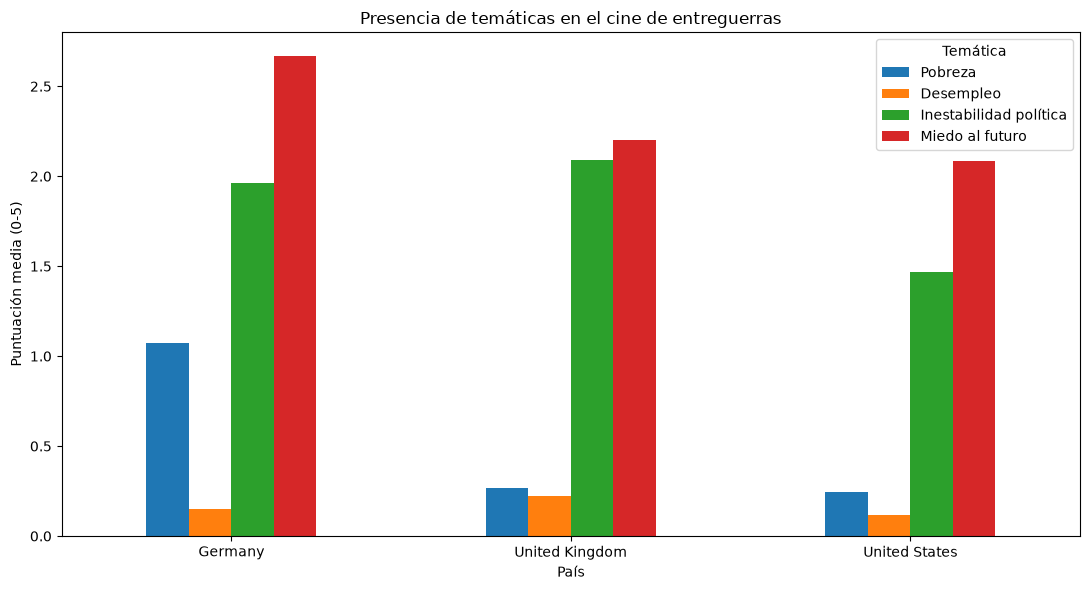

In [16]:
tematicas = ["poverty_score","unemployment_score","political_instability_score","fear_future_score"]

datos=peliculas_19_39_clasificado.groupby("paises_norm")[tematicas].mean()

datos.plot(kind="bar", figsize=(11, 6))

plt.title("Presencia de temáticas en el cine de entreguerras")
plt.xlabel("País")
plt.ylabel("Puntuación media (0-5)")
plt.xticks(rotation=0)
plt.legend(["Pobreza","Desempleo","Inestabilidad política","Miedo al futuro"], title="Temática")

plt.tight_layout()
plt.show()

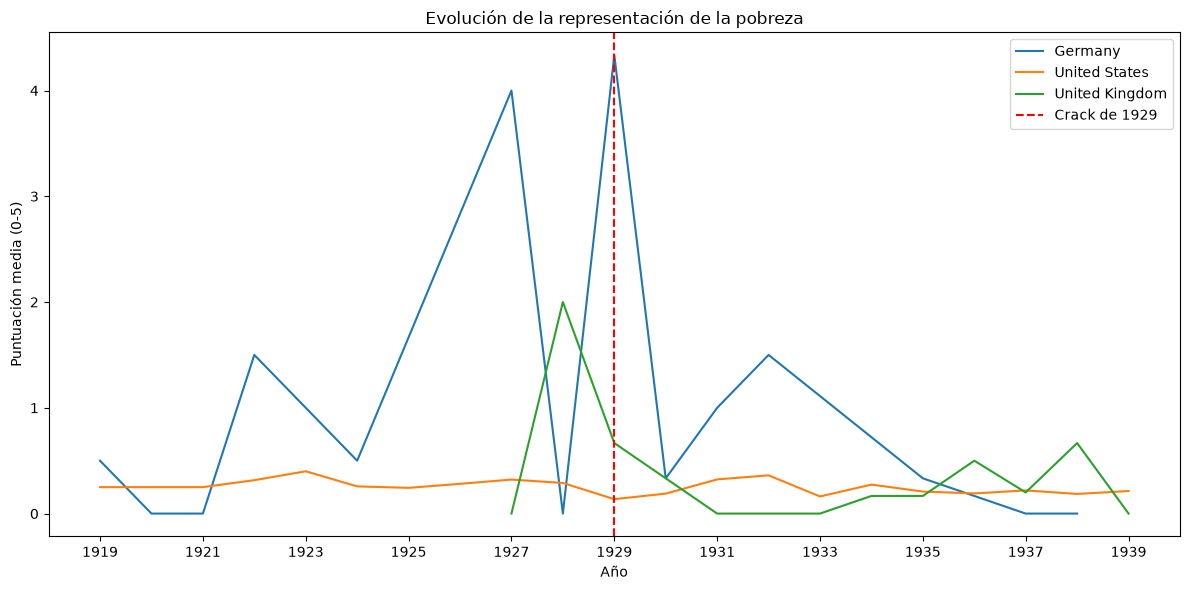

In [17]:
plt.figure(figsize=(12, 6))

sns.lineplot(data=peliculas_19_39_clasificado, x="release_year", y="poverty_score", hue="paises_norm", estimator="mean", errorbar=None)

plt.title("Evolución de la representación de la pobreza")
plt.xlabel("Año")
plt.ylabel("Puntuación media (0-5)")
plt.axvline(1929, linestyle="--", color="red", label="Crack de 1929")
plt.xticks(range(1919, 1940, 2))
plt.legend()
plt.tight_layout()

plt.show()

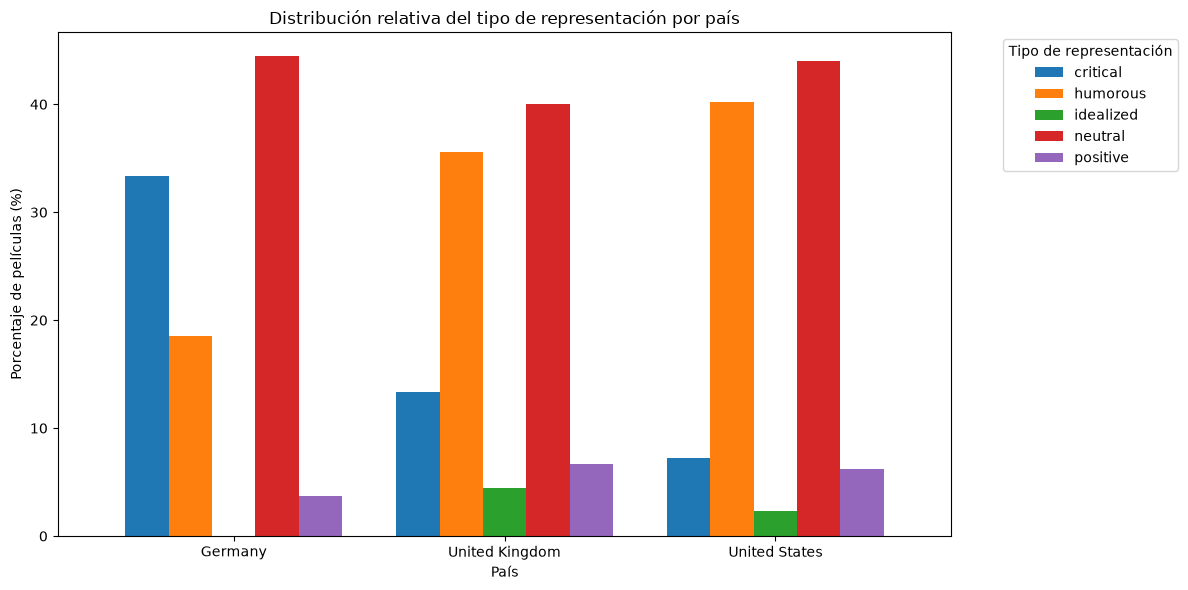

In [18]:
df_relativo = pd.crosstab(peliculas_19_39_clasificado["paises_norm"],peliculas_19_39_clasificado["representation_type"],normalize="index")*100

df_relativo.plot(kind="bar",figsize=(12, 6),width=0.8)

plt.title("Distribución relativa del tipo de representación por país")
plt.xlabel("País")
plt.ylabel("Porcentaje de películas (%)")
plt.xticks(rotation=0)
plt.legend(title="Tipo de representación", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

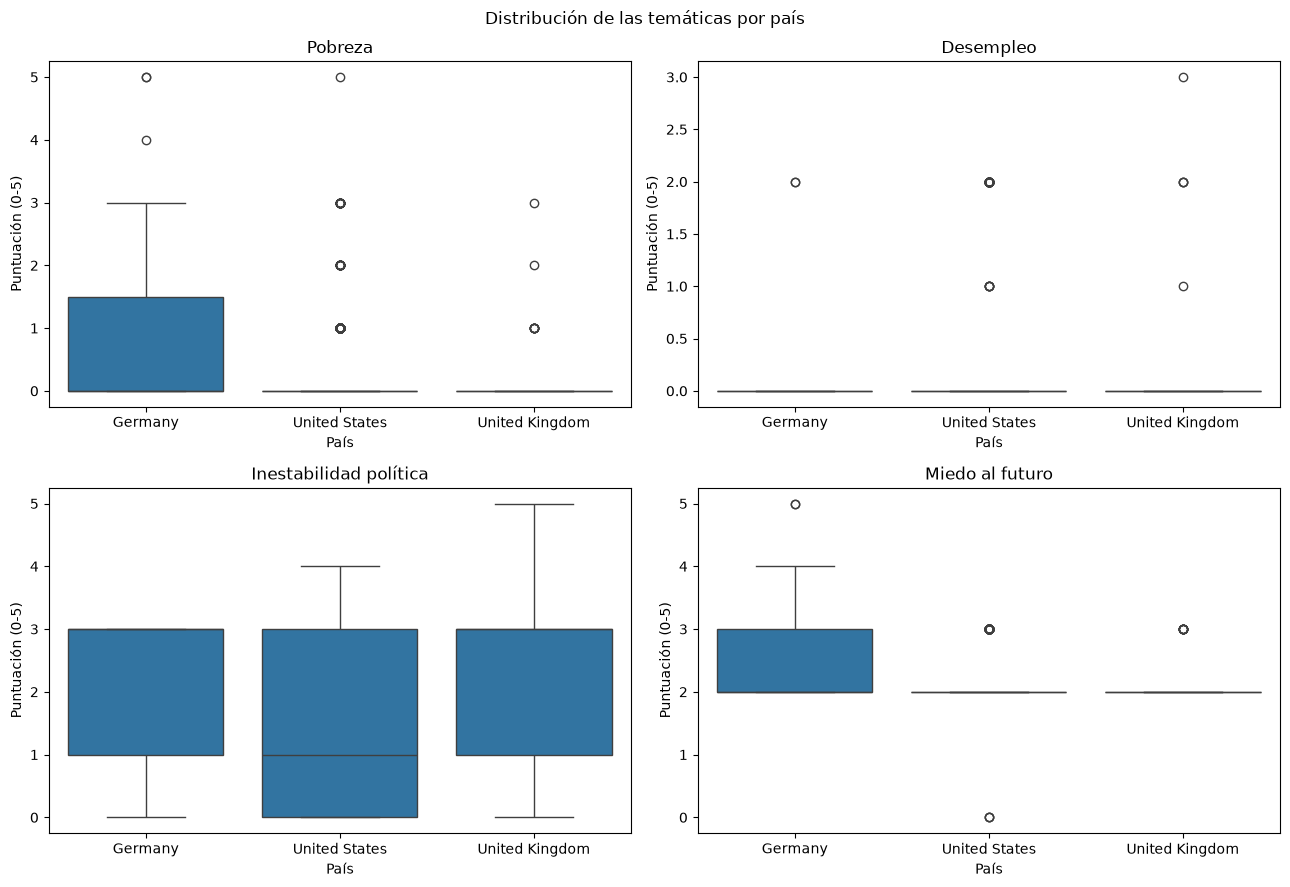

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

columnas = ["poverty_score","unemployment_score","political_instability_score","fear_future_score"]
titulos = ["Pobreza","Desempleo","Inestabilidad política","Miedo al futuro"]

for ax, columna, titulo in zip(axes.flat, columnas, titulos):
    sns.boxplot(data=peliculas_19_39_clasificado,x="paises_norm",y=columna,ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("País")
    ax.set_ylabel("Puntuación (0-5)")

plt.suptitle("Distribución de las temáticas por país")
plt.tight_layout()
plt.show()

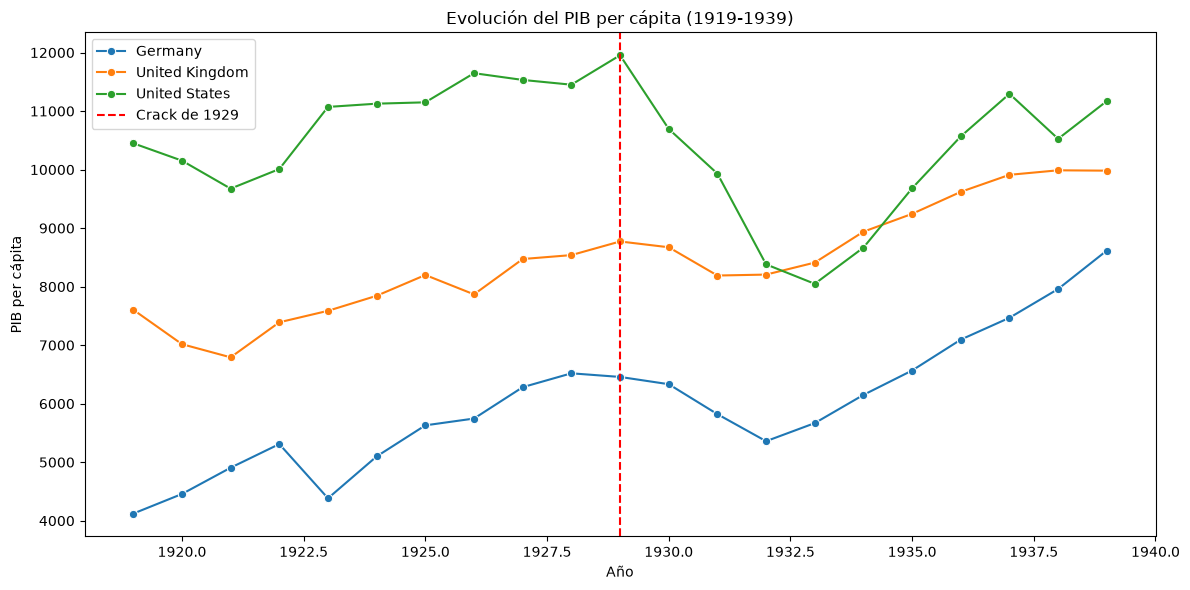

In [20]:
plt.figure(figsize=(12, 6))

sns.lineplot(data=df_social_1919_1939,x="year",y="GDP per capita",hue="country",marker="o")

plt.title("Evolución del PIB per cápita (1919-1939)")
plt.xlabel("Año")
plt.ylabel("PIB per cápita")
plt.axvline(1929, linestyle="--", color="red", label="Crack de 1929")
plt.legend()
plt.tight_layout()
plt.show()

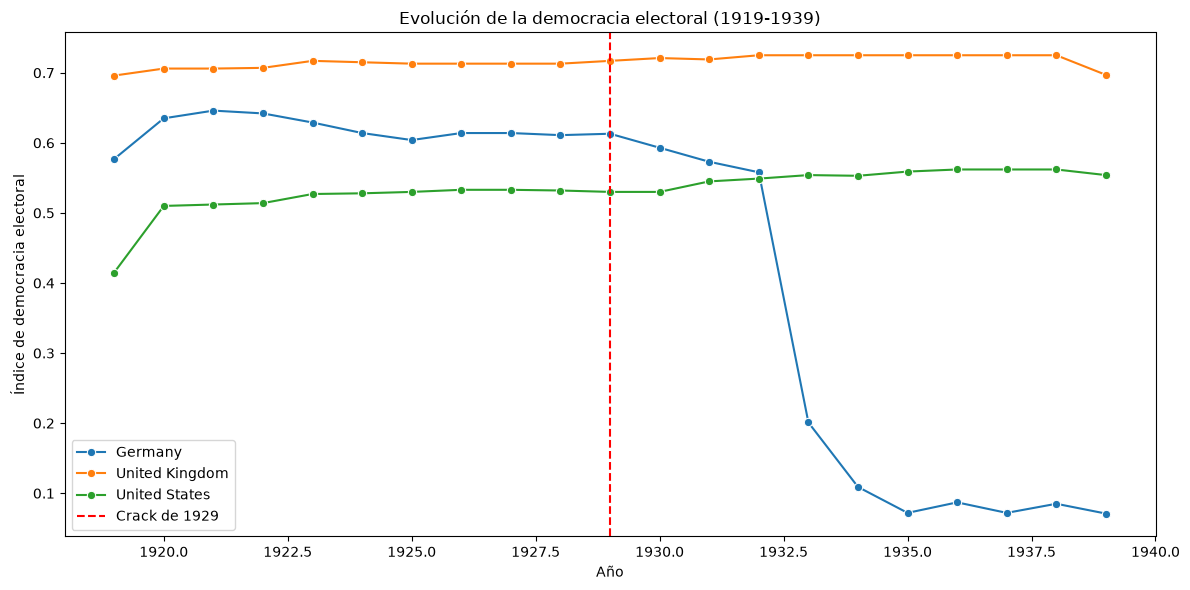

In [21]:
plt.figure(figsize=(12, 6))

sns.lineplot(data=df_social_1919_1939,x="year",y="v2x_polyarchy",hue="country",marker="o")

plt.title("Evolución de la democracia electoral (1919-1939)")
plt.xlabel("Año")
plt.ylabel("Índice de democracia electoral")
plt.axvline(1929, linestyle="--", color="red", label="Crack de 1929")
plt.legend()
plt.tight_layout()
plt.show()

Juntamos en un df nuevo (df_comparacion) el poverty_score, el political_instability_score, el GDP per Cápita u el v2x_polyarchy

In [22]:
df_peliculas = peliculas_19_39_clasificado.copy()

df_peliculas = df_peliculas.rename(columns={"release_year": "year"})

df_peliculas["country"] = df_peliculas["paises_norm"].str.split(", ")
df_peliculas = df_peliculas.explode("country")

paises = ["United States", "Germany", "United Kingdom"]

df_peliculas = df_peliculas[df_peliculas["country"].isin(paises)]

df_peliculas["year"] = pd.to_numeric(df_peliculas["year"], errors="coerce")

df_peliculas_anual = (df_peliculas.groupby(["country","year"], as_index=False)[["poverty_score", "political_instability_score"]].mean())

df_comparacion = pd.merge(df_peliculas_anual,df_social_1919_1939,on=["country", "year"],how="inner")

df_comparacion = df_comparacion.sort_values(["country", "year"])

df_comparacion.head()

,country,year,poverty_score,political_instability_score,GDP per capita,v2x_polyarchy
0,Germany,1919.0,0.5,2.0,4122.0,0.577
1,Germany,1920.0,0.0,1.0,4457.0,0.635
2,Germany,1921.0,0.0,3.0,4906.0,0.646
3,Germany,1922.0,1.5,3.0,5310.0,0.642
4,Germany,1924.0,0.5,2.0,5099.0,0.614


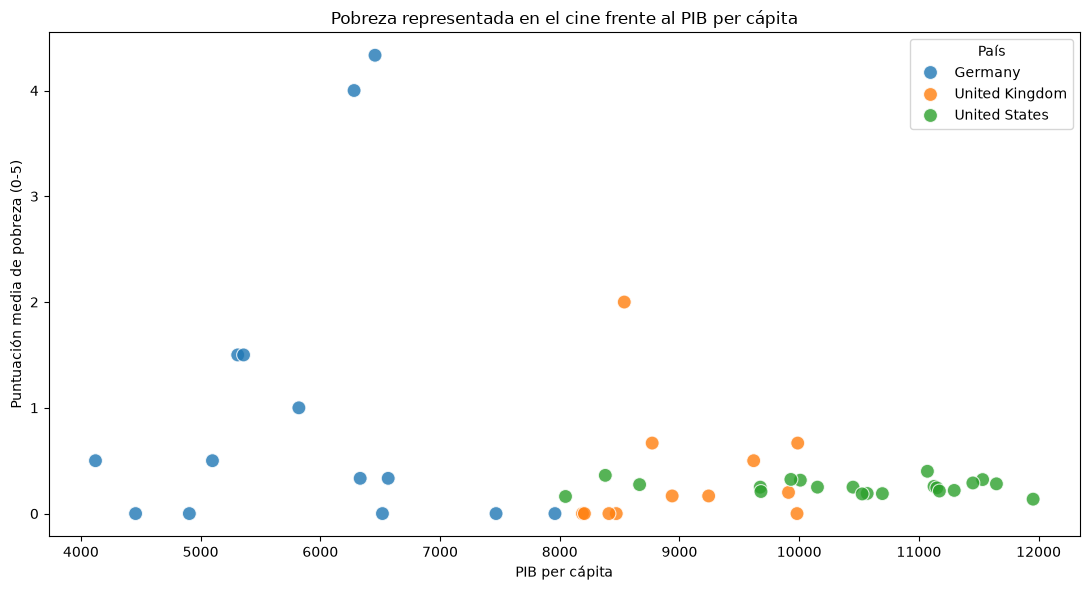

In [23]:
#Pobreza representada en el cine frente al PIB

plt.figure(figsize=(11, 6))

sns.scatterplot(data=df_comparacion,x="GDP per capita",y="poverty_score",hue="country",s=100,alpha=0.8)

plt.title("Pobreza representada en el cine frente al PIB per cápita")
plt.xlabel("PIB per cápita")
plt.ylabel("Puntuación media de pobreza (0-5)")
plt.legend(title="País")
plt.tight_layout()
plt.show()

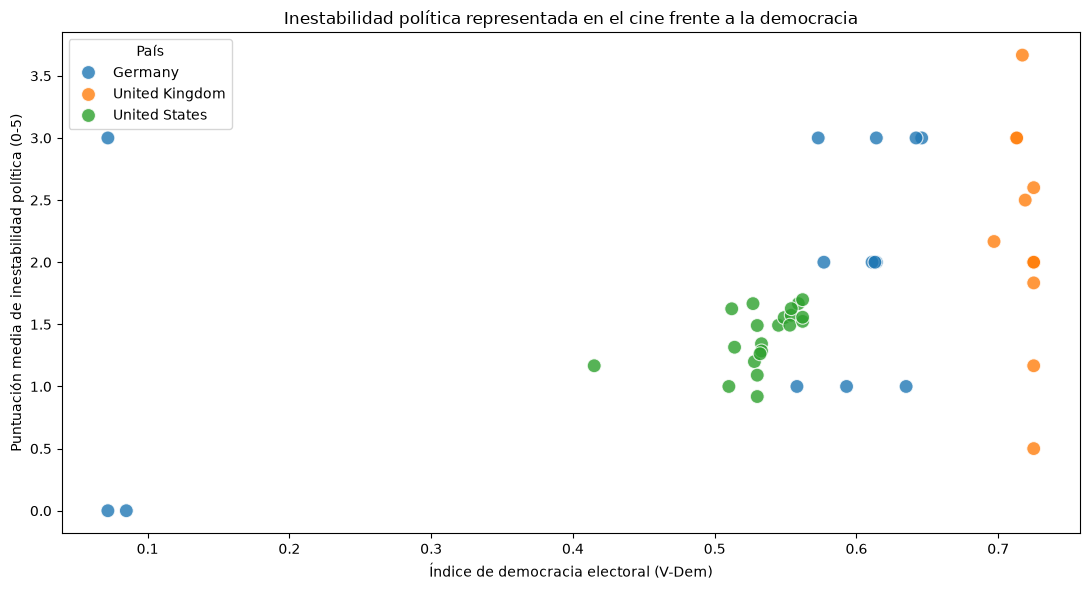

In [24]:
#Inestabilidad política representada en el cine frente a la democracia
plt.figure(figsize=(11,6))

sns.scatterplot(data=df_comparacion,x="v2x_polyarchy",y="political_instability_score",hue="country",s=100,alpha=0.8)

plt.title("Inestabilidad política representada en el cine frente a la democracia")
plt.xlabel("Índice de democracia electoral (V-Dem)")
plt.ylabel("Puntuación media de inestabilidad política (0-5)")
plt.legend(title="País")
plt.tight_layout()
plt.show()

In [25]:
df_comparacion_peliculas = pd.merge(df_peliculas,df_social_1919_1939,on=["country", "year"],how="inner")
df_comparacion_peliculas

,movie_id,title,original_title,year,director,genres,title_key,production_country,synopsis,languages,...,synopsis_words,poverty_score,unemployment_score,political_instability_score,fear_future_score,representation_type,classification_evidence,country,GDP per capita,v2x_polyarchy
0,tt0009878,Different from the Others,Anders als die Andern,1919.0,Richard Oswald,"Crime,Drama,History",different from the others,"Weimar Republic, Germany","Veidt portrays a successful violinist, Paul Kö...",German Language,...,745.0,0,0,3,4,critical,"Presenta contexto de conflicto bélico, huelgas...",Germany,4122.000,0.577
1,tt0009893,The Oyster Princess,Die Austernprinzessin,1919.0,Ernst Lubitsch,Comedy,the oyster princess,Weimar Republic,The American oyster King dictates to a room fu...,"Silent film, German Language, English Language",...,1937.0,1,0,1,2,humorous,Aparecen elementos o personajes de origen humi...,Germany,4122.000,0.577
2,tt0010040,Daddy-Long-Legs,Daddy-Long-Legs,1919.0,Marshall Neilan,"Comedy,Drama,Musical",daddy-long-legs,United States of America,"A police officer finds a baby in a trash can, ...","Silent film, English Language",...,217.0,2,0,2,2,humorous,Aparecen elementos o personajes de origen humi...,United States,10449.780,0.415
3,tt0010081,The Echo of Youth,The Echo of Youth,1919.0,Ivan Abramson,Drama,the echo of youth,United States of America,Cabaret singer Olive Martin approaches her fo...,NaN,...,130.0,0,0,1,3,neutral,"Aparecen instituciones políticas, procesos jud...",United States,10449.780,0.415
4,tt0010112,The False Faces,The False Faces,1919.0,Irvin Willat,"Drama,War",the false faces,United States of America,"During World War I, a professional thief known...","Silent film, English Language",...,55.0,0,0,3,2,neutral,"Presenta contexto de conflicto bélico, huelgas...",United States,10449.780,0.415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1050,tt0190518,The Lady of Red Butte,The Lady of Red Butte,1919.0,Victor Schertzinger,"Drama,Western",the lady of red butte,United States of America,Faro Fan inherits a saloon and gambling hall i...,"Silent film, English Language",...,53.0,1,0,0,2,neutral,Aparecen elementos o personajes de origen humi...,United States,10449.780,0.415
1051,tt0196971,St. Elmo,St. Elmo,1923.0,Rex Wilson,Drama,st. elmo,United States of America,When St. Elmo Thornton catches his fiancée Agn...,"Silent film, English Language",...,58.0,0,0,0,2,neutral,"Muestra temor al futuro, pánico a tragedias o ...",United States,11071.243,0.527
1052,tt0229868,Zwei Menschen,Zwei Menschen,1930.0,Erich Waschneck,Drama,zwei menschen,Germany,Junker Rochus and Judith Platter are in love. ...,German Language,...,78.0,0,0,0,3,neutral,"Muestra temor al futuro, pánico a tragedias o ...",Germany,6333.000,0.593
1053,tt0955292,The Lost City,The Lost City,1935.0,NaN,Sci-Fi,the lost city,United States of America,The film took the premise of that year's The P...,English Language,...,160.0,0,0,0,3,neutral,"Muestra temor al futuro, pánico a tragedias o ...",United States,9680.839,0.559


In [26]:
fig = px.scatter(
    df_comparacion_peliculas, x="GDP per capita", y="poverty_score", color="country",
    color_discrete_map={"United States": "#3498DB", "Germany": "#E67E22", "United Kingdom": "#2ECC71"},
    hover_name="title",
    hover_data={"country": True,"year": True,"GDP per capita": ":,.0f","poverty_score": True},
    title="Pobreza representada en cada película frente al PIB per cápita",
    labels={"GDP per capita": "PIB per cápita","poverty_score": "Puntuación de pobreza (0-5)","country": "País","year": "Año"},
    opacity=0.7
)

fig.update_traces(
    marker=dict(size=11),
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "País: %{customdata[0]}<br>"
        "Año: %{customdata[1]}<br>"
        "PIB per cápita: %{x:,.0f}<br>"
        "Puntuación de pobreza: %{y}"
        "<extra></extra>"
    )
)

fig.update_layout(width=1000,height=600,hoverlabel=dict(font_size=13),legend_title="País")

fig.show()

In [27]:
fig = px.scatter(
    df_comparacion_peliculas, x="v2x_polyarchy", y="political_instability_score", color="country",
    color_discrete_map={"United States": "#3498DB", "Germany": "#E67E22", "United Kingdom": "#2ECC71"},
    hover_name="title",
    hover_data={"country": True,"year": True,"v2x_polyarchy": ":.3f","political_instability_score": True},
    title="Inestabilidad política representada en cada película frente a la democracia",
    labels={
        "v2x_polyarchy": "Índice de democracia electoral (V-Dem)",
        "political_instability_score": "Puntuación de inestabilidad política (0-5)",
        "country": "País",
        "year": "Año"
    },
    opacity=0.7
)

fig.update_traces(
    marker=dict(size=11),
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "País: %{customdata[0]}<br>"
        "Año: %{customdata[1]}<br>"
        "Democracia electoral: %{x:.3f}<br>"
        "Inestabilidad política: %{y}"
        "<extra></extra>"
    )
)

fig.update_layout(width=1000,height=600,hoverlabel=dict(font_size=13),legend_title="País")

fig.show()

In [28]:
# from bokeh.plotting import figure, show
# from bokeh.models import (
#     ColumnDataSource,
#     HoverTool,
#     BoxAnnotation,
#     Span,
#     NumeralTickFormatter,
#     Legend,
#     LegendItem
# )
# from bokeh.palettes import Category10
# from bokeh.transform import factor_cmap
# from bokeh.io import output_notebook

# # --------------------------------------------------
# # 1. PREPARACIÓN DE LOS DATOS
# # --------------------------------------------------

# df = df_comparacion_peliculas.copy()

# # Eliminamos registros sin datos necesarios
# df = df.dropna(subset=[
#     "country",
#     "title",
#     "year",
#     "v2x_polyarchy",
#     "political_instability_score"
# ])

# source = ColumnDataSource(df)

# # Países disponibles
# paises = sorted(df["country"].unique())

# # Colores
# paleta = Category10[10][:len(paises)]

# # --------------------------------------------------
# # 2. CREACIÓN DEL GRÁFICO
# # --------------------------------------------------

# fig = figure(
#     width=1100,
#     height=700,

#     title="EL ESPEJO DEL MUNDO | Democracia e inestabilidad política",

#     x_axis_label="Índice de democracia electoral (V-Dem)",
#     y_axis_label="Representación de la inestabilidad política (0-5)",

#     x_range=(-0.05, 1.05),
#     y_range=(-0.3, 5.4),

#     tools="pan,wheel_zoom,box_zoom,lasso_select,box_select,reset,save",

#     toolbar_location="above",

#     background_fill_color="#17212B",
#     border_fill_color="#17212B",
#     outline_line_color="#34495E"
# )

# # --------------------------------------------------
# # 3. ESTILO GENERAL
# # --------------------------------------------------

# # Título
# fig.title.text_color = "#FFFFFF"
# fig.title.text_font = "Arial"
# fig.title.text_font_size = "17pt"
# fig.title.text_font_style = "bold"
# fig.title.align = "center"

# # Ejes
# fig.xaxis.axis_label_text_color = "#FFFFFF"
# fig.yaxis.axis_label_text_color = "#FFFFFF"

# fig.xaxis.axis_label_text_font_size = "12pt"
# fig.yaxis.axis_label_text_font_size = "12pt"

# fig.xaxis.major_label_text_color = "#D5D8DC"
# fig.yaxis.major_label_text_color = "#D5D8DC"

# fig.xaxis.major_label_text_font_size = "10pt"
# fig.yaxis.major_label_text_font_size = "10pt"

# # Cuadrícula
# fig.xgrid.grid_line_color = "#52616B"
# fig.ygrid.grid_line_color = "#52616B"

# fig.xgrid.grid_line_alpha = 0.25
# fig.ygrid.grid_line_alpha = 0.25

# # Bordes
# fig.outline_line_width = 1.5

# # Formato del eje X
# fig.xaxis.formatter = NumeralTickFormatter(format="0.00")

# # --------------------------------------------------
# # 4. ZONAS DE REFERENCIA
# # --------------------------------------------------

# # Zona de baja democracia
# zona_baja_democracia = BoxAnnotation(
#     left=0,
#     right=0.3,
#     fill_color="#E74C3C",
#     fill_alpha=0.08
# )

# fig.add_layout(zona_baja_democracia)

# # Zona de alta democracia
# zona_alta_democracia = BoxAnnotation(
#     left=0.7,
#     right=1,
#     fill_color="#2ECC71",
#     fill_alpha=0.06
# )

# fig.add_layout(zona_alta_democracia)

# # Línea horizontal: puntuación 2.5
# linea_inestabilidad = Span(
#     location=2.5,
#     dimension="width",
#     line_color="#F1C40F",
#     line_dash="dashed",
#     line_width=2,
#     line_alpha=0.8
# )

# fig.add_layout(linea_inestabilidad)

# # --------------------------------------------------
# # 5. DIBUJAR LOS PUNTOS
# # --------------------------------------------------

# renderer = fig.scatter(
#     x="v2x_polyarchy",
#     y="political_instability_score",

#     source=source,

#     size=13,
#     alpha=0.8,

#     color=factor_cmap(
#         "country",
#         palette=paleta,
#         factors=paises
#     ),

#     line_color="#FFFFFF",
#     line_width=0.8,

#     selection_color="#FFFFFF",
#     selection_alpha=1,

#     nonselection_alpha=0.12
# )

# # --------------------------------------------------
# # 6. HOVER PERSONALIZADO
# # --------------------------------------------------

# hover = HoverTool(
#     renderers=[renderer],

#     tooltips="""
#     <div style="
#         background-color: #17212B;
#         padding: 12px;
#         border-radius: 8px;
#         border: 1px solid #52616B;
#         min-width: 240px;
#     ">

#         <div style="
#             color: #F1C40F;
#             font-size: 14px;
#             font-weight: bold;
#             margin-bottom: 10px;
#         ">
#             @title
#         </div>

#         <div style="color: #FFFFFF; font-size: 12px;">
#             <b>País:</b> @country
#         </div>

#         <div style="color: #FFFFFF; font-size: 12px;">
#             <b>Año:</b> @year
#         </div>

#         <hr style="border: 0; border-top: 1px solid #52616B;">

#         <div style="color: #5DADE2; font-size: 12px;">
#             <b>Democracia electoral:</b> @v2x_polyarchy{0.000}
#         </div>

#         <div style="color: #E67E22; font-size: 12px;">
#             <b>Inestabilidad política:</b>
#             @political_instability_score{0.0} / 5
#         </div>

#     </div>
#     """
# )

# fig.add_tools(hover)

# # --------------------------------------------------
# # 7. LEYENDA INTERACTIVA
# # --------------------------------------------------

# fig.legend.title = "País de producción"
# fig.legend.location = "top_right"
# fig.legend.label_text_color = "#FFFFFF"
# fig.legend.title_text_color = "#F1C40F"

# fig.legend.label_text_font_size = "10pt"
# fig.legend.title_text_font_size = "11pt"

# fig.legend.background_fill_color = "#17212B"
# fig.legend.background_fill_alpha = 0.9

# fig.legend.border_line_color = "#52616B"
# fig.legend.border_line_alpha = 0.8

# fig.legend.click_policy = "hide"

# # --------------------------------------------------
# # 8. HERRAMIENTAS INTERACTIVAS
# # --------------------------------------------------

# fig.toolbar.logo = None
# fig.toolbar.autohide = True

# # --------------------------------------------------
# # 9. MOSTRAR GRÁFICO
# # --------------------------------------------------

# show(fig)